# 3. The moment

Knowing a pest is around is half an answer. The other half is **when it
matters**.

Helopeltis feeds on *tender shoots* — the young flush. A mature leaf is a much
lower-value target. So the same detection means something different depending on
what the plant is doing:

| stage | meaning |
|---|---|
| `new_flush` | tender shoot — **the risk window** |
| `mature_leaf` | hardened leaf — lower risk |

This is the **WHEN** dimension, and it is what turns a detection into a risk
score rather than a fact.

In [1]:
import json, os, sys, warnings
from pathlib import Path

# Keep library warnings out of the saved output.
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["figure.dpi"] = 110
print("project root:", ROOT.name)

project root: TeaGuard


In [2]:
from src.pipeline import FlushClassifier

flush = FlushClassifier()
print("classifier loaded :", flush.available)
print("classes           :", flush.CLASSES)
print("decision threshold:", flush.NEW_FLUSH_THRESHOLD, "for new_flush")

classifier loaded : True
classes           : ['new_flush', 'mature_leaf']
decision threshold: 0.5 for new_flush


That threshold is plain 0.5, and that is a result, not a default.

Missing a tender-shoot window is the expensive error, so the first version
lowered the threshold to 0.35 to buy recall on the high-risk class. That value
had been tuned on the contaminated split. Re-swept on the capture-session
split, no threshold between 0.20 and 0.80 beats 0.5 on macro-F1, and 0.35 cost
more precision than it bought recall (test accuracy 0.686 vs 0.731). The trade
it assumed does not exist in this model.

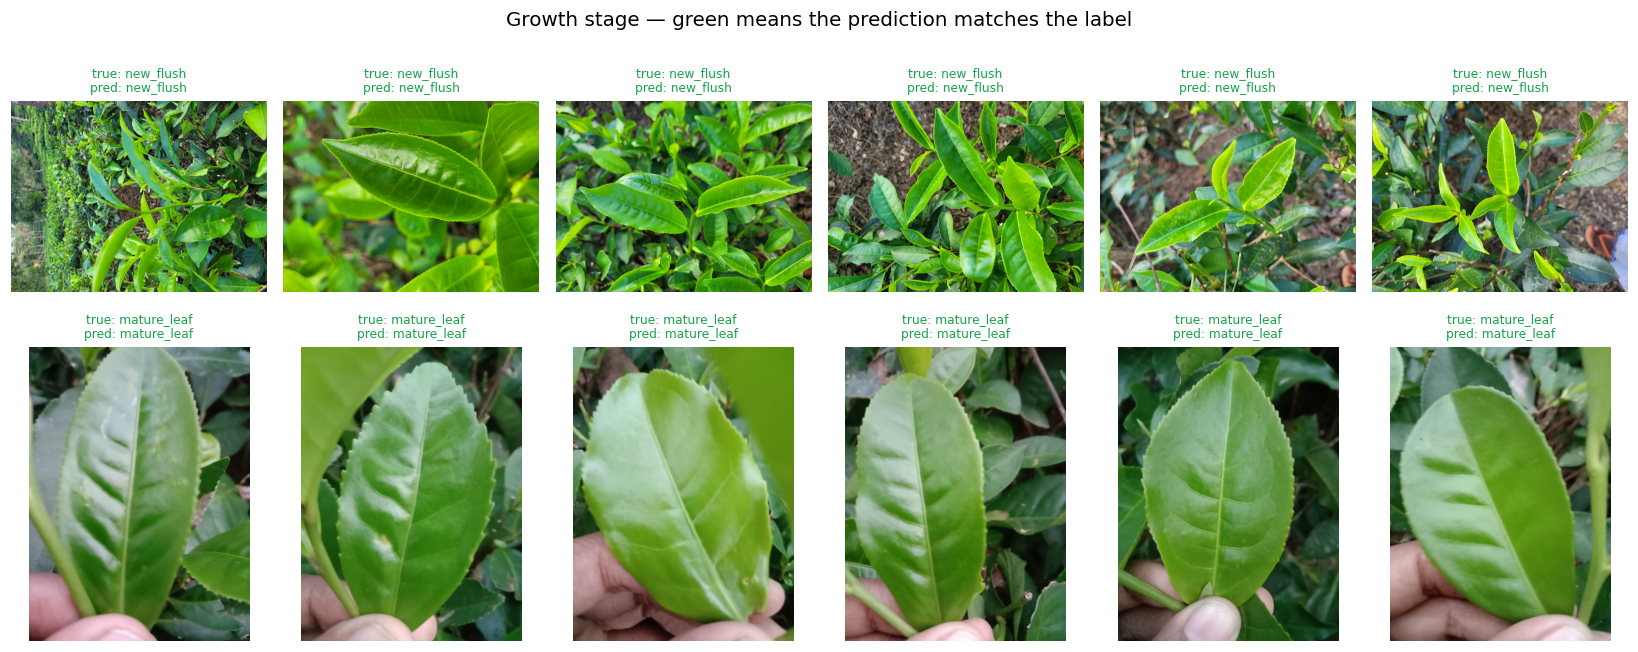

In [3]:
FLUSH = ROOT / "data" / "raw" / "flush_stages"
samples = ([(p, "new_flush") for p in sorted((FLUSH / "new_flush").glob("*.jpg"))[:6]]
           + [(p, "mature_leaf") for p in sorted((FLUSH / "mature_leaf").glob("*.jpg"))[:6]])

fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, (path, truth) in zip(axes.ravel(), samples):
    img = np.array(Image.open(path).convert("RGB"))
    pred = flush.predict(img)
    ok = pred == truth
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"true: {truth}\npred: {pred}", fontsize=8,
                 color="#16a34a" if ok else "#dc2626")
fig.suptitle("Growth stage — green means the prediction matches the label", fontsize=13)
plt.tight_layout(); plt.show()

In [4]:
fm = json.loads((ROOT / "models" / "flush_stage_metrics.json").read_text())
print(json.dumps(fm, indent=2)[:1200])

{
  "classes": [
    "new_flush",
    "mature_leaf"
  ],
  "split": "capture session (70/15/15), sessions kept whole",
  "n_sessions": 20,
  "n_train": 1267,
  "n_val": 451,
  "n_test": 490,
  "report": "              precision    recall  f1-score   support\n\n   new_flush      0.429     0.642     0.515       109\n mature_leaf      0.881     0.756     0.814       381\n\n    accuracy                          0.731       490\n   macro avg      0.655     0.699     0.664       490\nweighted avg      0.780     0.731     0.747       490\n",
  "confusion_matrix": [
    [
      70,
      39
    ],
    [
      93,
      288
    ]
  ]
}


## Limits

- Two classes only. A `dormant` stage exists in reality (lowest pest activity)
  but has no public dataset, so it is deliberately out of scope.
- Same domain caveat as everything else here: these are not plantation photos.

Next: [4. The verdict](04_the_verdict.ipynb) — the three readings together.